## Some basic math calculations related to decision trees

**See the materials and the walkthrough how all this maps to visualization of decision trees**

In [54]:
import pandas as pd

# our test data, study hours + attendance % => does the student pass the exam or not?
rows = [
    ["yes", "low", "often"],
    ["yes", "high", "rarely"],
    ["no", "low", "rarely"],
    ["yes", "high", "rarely"],
    ["no", "low", "rarely"],
    ["yes", "low", "often"],
    ["yes", "high", "rarely"],
    ["no", "low", "rarely"],
    ["yes", "low", "often"],
    ["no", "low", "rarely"],
    ["yes", "high", "rarely"],
    ["no", "low", "rarely"],
    ["yes", "high", "often"],
    ["no", "low", "rarely"],
    ["yes", "high", "often"]
]

# column names
column_names = ["Pass Exam", "Study Hours", "Attending Lectures"]

# create a DataFrame out of the lists
df = pd.DataFrame(columns=column_names, data=rows)
df.head()

,Pass Exam,Study Hours,Attending Lectures
0,yes,low,often
1,yes,high,rarely
2,no,low,rarely
3,yes,high,rarely
4,no,low,rarely


In [55]:
# get the crosstab for study hours when compared to Pass Exam
hours_ct = pd.crosstab(df['Study Hours'], df['Pass Exam'])
hours_ct

Pass Exam,no,yes
Study Hours,,
high,0,6
low,6,3


In [56]:
# helper variable for gini index calculations
filter = "high"
high_yes = hours_ct.loc[:, "yes"][filter]
high_no = hours_ct.loc[:, "no"][filter]
high_total = high_yes + high_no

In [57]:
# helper variable for gini index calculations
filter = "low"
low_yes = hours_ct.loc[:, "yes"][filter]
low_no = hours_ct.loc[:, "no"][filter]
low_total = low_yes + low_no

In [58]:
# get the gini index for high
gini_high = 1 - (high_yes / high_total) ** 2 - (high_no / high_total) ** 2
gini_high

np.float64(0.0)

In [59]:
# get the gini index for low
gini_low = 1 - (low_yes / low_total) ** 2 - (low_no / low_total) ** 2
gini_low

np.float64(0.4444444444444444)

0.0 for high-yes means we can fully explain the logic behind this => all students who had high study hours => always pass the exam => study hours is our ROOT NODE

In [60]:
# get the crosstab for study hours when compared to Pass Exam
attendance_ct = pd.crosstab(df['Attending Lectures'], df['Pass Exam'])
attendance_ct

Pass Exam,no,yes
Attending Lectures,,
often,0,5
rarely,6,4


In [61]:
# helper variable for gini index calculations
filter = "often"
often_yes = attendance_ct.loc[:, "yes"][filter]
often_no = attendance_ct.loc[:, "no"][filter]
often_total = often_yes + often_no

In [62]:
# helper variable for gini index calculations
filter = "rarely"
rarely_yes = attendance_ct.loc[:, "yes"][filter]
rarely_no = attendance_ct.loc[:, "no"][filter]
rarely_total = rarely_yes + rarely_no

In [63]:
# get the gini index for often
gini_often = 1 - (often_yes / often_total) ** 2 - (often_no / often_total) ** 2
gini_often

np.float64(0.0)

In [64]:
# get the gini index for rarely
gini_rarely = 1 - (rarely_yes / rarely_total) ** 2 - (rarely_no / rarely_total) ** 2
gini_rarely

np.float64(0.48)

**This would roughly amount to a following decision tree:**

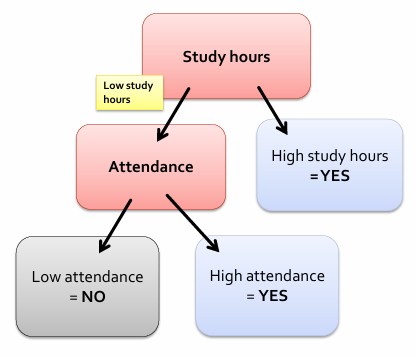